# Machine Learning – Assignment 2: Classification Models + Streamlit Deployment
**M.Tech (DSE) · WILP, BITS Pilani · 15 marks**

**Dataset:** Online Shoppers Purchasing Intention (UCI Machine Learning Repository, id 468)
**Models:** Logistic Regression · Decision Tree · k-Nearest Neighbours · Naive Bayes (Gaussian) · Support Vector Machine
**Metrics:** Accuracy · AUC · Precision · Recall · F1 · MCC

---
### How to use this notebook
1. Run it top to bottom on the **BITS Virtual Lab** and take **one screenshot** that shows the environment cell (Section 1) and the results table (Section 7). That is the 1-mark lab proof.
2. The notebook produces everything the GitHub repo needs: `model/*.joblib`, `test_data.csv`, `requirements.txt`, `model/feature_info.json` and `README_tables.md` (comparison table to paste into the README).
3. Section 8 (observations) is left for **you** to write after reading your own output. Those 3 marks should come from your actual numbers.

## 0. Problem statement

An e-commerce site wants to know, **while a visitor's session is still being recorded, whether that session will end in a purchase.** Each row of the dataset describes one browsing session (pages viewed, time spent, Google Analytics metrics, visitor and technical details) and the target `Revenue` says whether a transaction was completed.

This is a **binary classification** problem with **class imbalance** (most sessions do not end in a purchase), so accuracy alone is misleading. AUC, Recall, F1 and MCC matter here, and that is why the assignment asks for all six metrics.

## 0.1 Dataset description

| Item | Detail |
|---|---|
| Source | UCI Machine Learning Repository – *Online Shoppers Purchasing Intention Dataset* (Sakar & Kastro, 2018), licence CC BY 4.0 |
| Link | https://archive.ics.uci.edu/dataset/468 |
| Instances | 12,330 sessions (before duplicate removal) |
| Features | 17 input features (10 numeric, 7 categorical/binary) + target `Revenue` |
| Task | Binary classification – did the session end in a purchase? |

**Feature groups**
- *Page-type activity:* `Administrative`, `Administrative_Duration`, `Informational`, `Informational_Duration`, `ProductRelated`, `ProductRelated_Duration` – number of pages of each type visited and time spent on them.
- *Google Analytics metrics:* `BounceRates`, `ExitRates`, `PageValues`.
- *Calendar:* `SpecialDay` (closeness of the visit to a special day such as Valentine's Day), `Month`, `Weekend`.
- *Visitor / technical:* `OperatingSystems`, `Browser`, `Region`, `TrafficType`, `VisitorType`.
- *Target:* `Revenue` (True = purchase).

Requirement check: minimum 12 features and 500 instances – both satisfied (verified in code below).

In [3]:
%pip install scikit-learn pandas numpy matplotlib seaborn joblib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.2/9.2 MB 76.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.3/35.3 MB 137.6 MB/s eta 0:00:0000:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.7/16.7 MB 145.7 MB/s eta 0:00:00
  Attempting uninstall: numpy
    Found existing installation: numpy 1.26.4
    Uninstalling numpy-1.26.4:
      Successfully uninstalled numpy-1.26.4
Note: you may need to restart the kernel to use updated packages.


## 1. Setup and environment (screenshot this for the BITS Lab proof)

In [1]:
# Standard library: file handling, timing, JSON, system info, downloading and unzipping the dataset
import os, sys, io, time, json, platform, warnings, zipfile, datetime, urllib.request

# Data handling and plotting
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
# joblib saves/loads trained models; scikit-learn provides the ML tools below
import joblib
import sklearn
from IPython.display import display, Markdown

# Splitting the data, cross-validation and hyper-parameter search
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
# Preprocessing: different transforms for numeric vs categorical columns, chained with the model
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
# The five classifiers required by the assignment
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
# Evaluation metrics and plotting helpers
from sklearn.metrics import (accuracy_score, roc_auc_score, precision_score, recall_score,
                             f1_score, matthews_corrcoef, confusion_matrix,
                             ConfusionMatrixDisplay, classification_report, roc_curve)

# Hide non-critical warnings to keep the output readable
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
# Fixed seed so every run gives the same split and results
RANDOM_STATE = 42

# Environment details: include this cell in your BITS Virtual Lab screenshot
print("Run time      :", datetime.datetime.now().strftime("%d-%b-%Y %H:%M:%S"))
print("Host          :", platform.node())
print("Platform      :", platform.platform())
print("Python        :", sys.version.split()[0])
print("scikit-learn  :", sklearn.__version__)
print("pandas / numpy:", pd.__version__, "/", np.__version__)
print("Working dir   :", os.getcwd())

Run time      : 08-Nov-2026 16:44:01
Host          : ip-10-3-22-135.ap-south-1.compute.internal
Platform      : Linux-5.14.0-503.14.1.el9_5.x86_64-x86_64-with-glibc2.34
Python        : 3.12.7
scikit-learn  : 1.9.1
pandas / numpy: 2.2.3 / 2.5.4
Working dir   : /home/s2025ns04073/Downloads


## 2. Load the dataset

The loader tries, in order: (1) a local `online_shoppers_intention.csv` next to the notebook, (2) the UCI zip download, (3) the `ucimlrepo` package. If the lab has no internet access, download the CSV manually from the UCI page above and place it next to this notebook.

In [3]:
# Where to look for / download the data, and the name of the target column
LOCAL_CSV = "online_shoppers_intention.csv"
ZIP_URL = "https://archive.ics.uci.edu/static/public/468/online+shoppers+purchasing+intention+dataset.zip"
TARGET = "Revenue"

# Try three sources in order: local file -> UCI zip download -> ucimlrepo package
def load_raw_data():
    if os.path.exists(LOCAL_CSV):
        print("Loaded local copy:", LOCAL_CSV)
        return pd.read_csv(LOCAL_CSV)
    # Option 2: download the zip from UCI, read the CSV inside it and cache it locally
    try:
        with urllib.request.urlopen(ZIP_URL, timeout=60) as resp:
            z = zipfile.ZipFile(io.BytesIO(resp.read()))
        csv_name = [n for n in z.namelist() if n.lower().endswith(".csv")][0]
        data = pd.read_csv(z.open(csv_name))
        data.to_csv(LOCAL_CSV, index=False)
        print("Downloaded from UCI and cached as", LOCAL_CSV)
        return data
    except Exception as e:
        print("Zip download failed:", repr(e)[:150])
    # Option 3: fetch through the ucimlrepo package (dataset id 468) and cache it locally
    try:
        from ucimlrepo import fetch_ucirepo
        ds = fetch_ucirepo(id=468)
        data = pd.concat([ds.data.features, ds.data.targets], axis=1)
        data.to_csv(LOCAL_CSV, index=False)
        print("Loaded via ucimlrepo and cached as", LOCAL_CSV)
        return data
    except Exception as e:
        print("ucimlrepo failed:", repr(e)[:150])
    raise RuntimeError("Could not fetch the dataset. Download online_shoppers_intention.csv from "
                       "https://archive.ics.uci.edu/dataset/468 and place it next to this notebook.")

# Load, tidy column names, and convert the target and Weekend from True/False to 1/0
df = load_raw_data()
df.columns = df.columns.str.strip()
df[TARGET] = df[TARGET].astype(int)
if "Weekend" in df.columns:
    df["Weekend"] = df["Weekend"].astype(int)

print("\nShape as downloaded:", df.shape)
display(df.head())

Downloaded from UCI and cached as online_shoppers_intention.csv

Shape as downloaded: (12330, 18)


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,0,0
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,0,0
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,0,0
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,0,0
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,1,0


## 3. Dataset checks

In [5]:
# Data quality: count duplicate rows and missing values
n_dup = df.duplicated().sum()
print(f"Exact duplicate rows : {n_dup}")
print(f"Missing values total : {int(df.isna().sum().sum())}")

# Exact duplicates can land in both train and test and inflate scores, so drop them.
df = df.drop_duplicates().reset_index(drop=True)

# Confirm the dataset meets the assignment's size requirements (fails loudly if not)
n_rows, n_cols = df.shape
n_features = n_cols - 1
print(f"After de-duplication : {n_rows} rows, {n_features} features + 1 target")
assert n_features >= 12, "Assignment needs at least 12 features"
assert n_rows >= 500,   "Assignment needs at least 500 instances"
print("Assignment size requirements satisfied (>=12 features, >=500 instances).")

# Column groups used by the preprocessing step.
# The four integer ID columns are labels (not quantities), so they are one-hot encoded with the others.
CATEGORICAL = ["Month", "VisitorType", "OperatingSystems", "Browser", "Region", "TrafficType"]
NUMERIC = [c for c in df.columns if c not in CATEGORICAL + [TARGET]]
assert set(CATEGORICAL) <= set(df.columns), "Unexpected column names in the dataset"
print("\nNumeric    :", NUMERIC)
print("Categorical:", CATEGORICAL)

# Class balance: how many sessions fall in each outcome
class_counts = df[TARGET].value_counts().sort_index()
class_pct = (class_counts / len(df) * 100).round(2)
display(pd.DataFrame({"count": class_counts, "percent": class_pct}).rename(index={0: "0 - no purchase", 1: "1 - purchase"}))
# Summary statistics of the numeric features
display(df[NUMERIC].describe().T.round(3))

Exact duplicate rows : 125
Missing values total : 0
After de-duplication : 12205 rows, 17 features + 1 target
Assignment size requirements satisfied (>=12 features, >=500 instances).

Numeric    : ['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay', 'Weekend']
Categorical: ['Month', 'VisitorType', 'OperatingSystems', 'Browser', 'Region', 'TrafficType']


,count,percent
Revenue,,
0 - no purchase,10297,84.37
1 - purchase,1908,15.63


,count,mean,std,min,25%,50%,75%,max
Administrative,12205.0,2.339,3.330,0.0,0.000,1.000,4.000,27.000
Administrative_Duration,12205.0,81.646,177.492,0.0,0.000,9.000,94.700,3398.750
Informational,12205.0,0.509,1.276,0.0,0.000,0.000,0.000,24.000
Informational_Duration,12205.0,34.825,141.425,0.0,0.000,0.000,0.000,2549.375
ProductRelated,12205.0,32.046,44.594,0.0,8.000,18.000,38.000,705.000
ProductRelated_Duration,12205.0,1206.982,1919.601,0.0,193.000,608.943,1477.155,63973.522
BounceRates,12205.0,0.020,0.045,0.0,0.000,0.003,0.017,0.200
ExitRates,12205.0,0.041,0.046,0.0,0.014,0.025,0.049,0.200
PageValues,12205.0,5.950,18.654,0.0,0.000,0.000,0.000,361.764
SpecialDay,12205.0,0.062,0.200,0.0,0.000,0.000,0.000,1.000


From the above table we see, 84.37% of sessions are “no purchase” (0) and 15.63% are “purchase”(1)

## 4. Exploratory data analysis

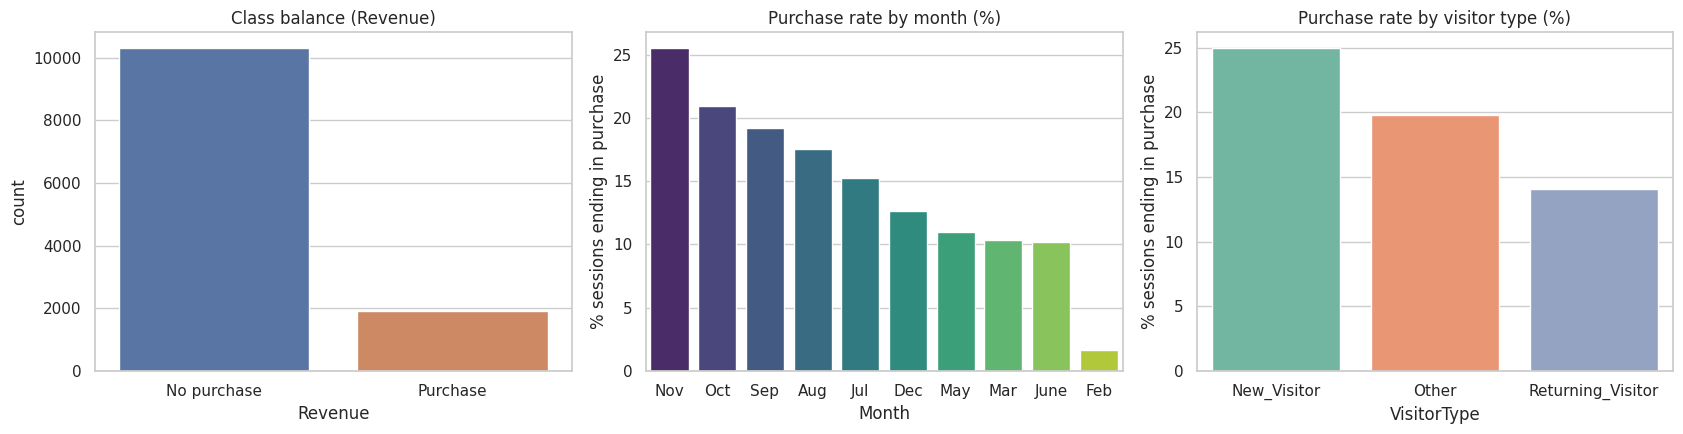

In [12]:
# Three panels: class balance, purchase rate by month, purchase rate by visitor type
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

sns.countplot(x=TARGET, hue=TARGET, data=df, ax=axes[0],
              palette=["#4C72B0", "#DD8452"], legend=False)
axes[0].set_title("Class balance (Revenue)")
axes[0].set_xticklabels(["No purchase", "Purchase"])

# The mean of the 0/1 target is the share of sessions that ended in a purchase
conv_month = df.groupby("Month")[TARGET].mean().sort_values(ascending=False) * 100
# Purchase rate by month: one colour per bar
sns.barplot(x=conv_month.index, y=conv_month.values, hue=conv_month.index,
            palette="viridis", ax=axes[1], legend=False)
axes[1].set_title("Purchase rate by month (%)")
axes[1].set_ylabel("% sessions ending in purchase")

conv_vis = df.groupby("VisitorType")[TARGET].mean() * 100
# Purchase rate by visitor type: one colour per bar
sns.barplot(x=conv_vis.index, y=conv_vis.values, hue=conv_vis.index,
            palette="Set2", ax=axes[2], legend=False)
axes[2].set_title("Purchase rate by visitor type (%)")
axes[2].set_ylabel("% sessions ending in purchase")

plt.tight_layout(); plt.show()

Insights: Most sessions end without a purchase (about 84%), while the purchase rate peaks in Nov at roughly 25% and is highest for New Visitor type at roughly 25%, so both month and visitor type carry predictive signal.

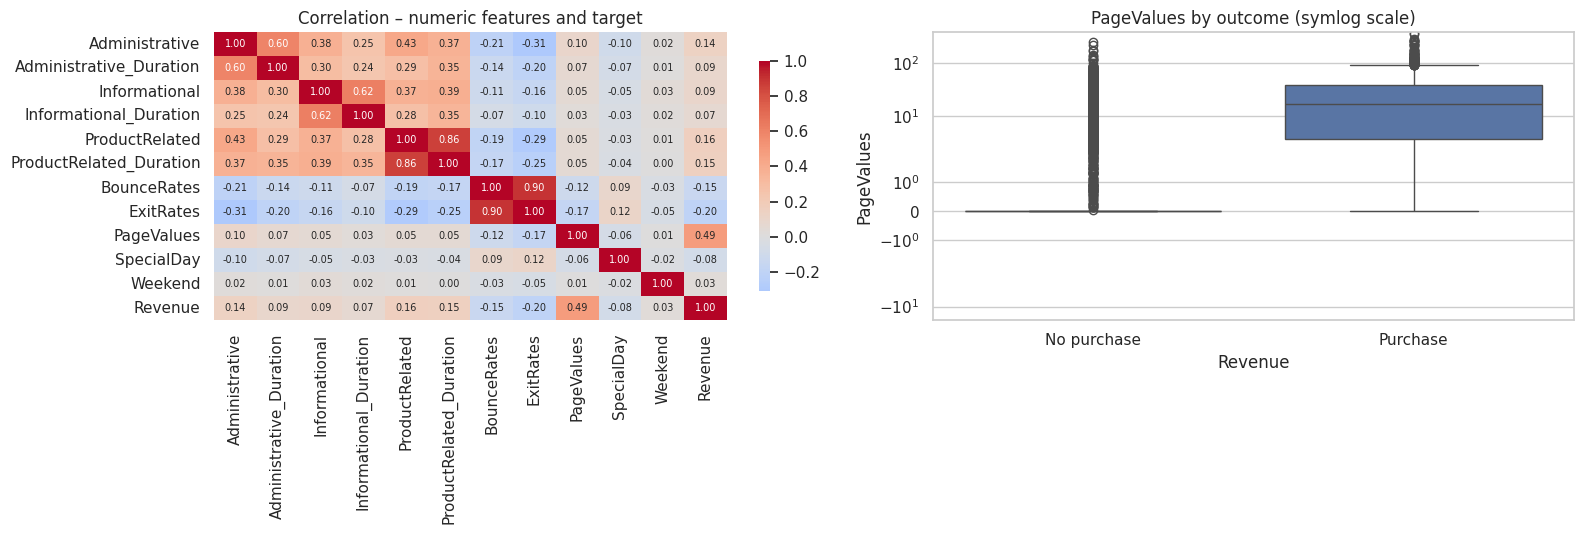

Numeric features most correlated with Revenue:
PageValues                 0.492
ExitRates                 -0.204
ProductRelated             0.156
ProductRelated_Duration    0.150
BounceRates               -0.145


In [16]:
# Left: correlation between numeric features and the target. Right: PageValues split by outcome
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))

corr = df[NUMERIC + [TARGET]].corr()
sns.heatmap(corr, cmap="coolwarm", center=0, ax=axes[0], annot=True, fmt=".2f", annot_kws={"size": 7},
            cbar_kws={"shrink": 0.8})
axes[0].set_title("Correlation – numeric features and target")

sns.boxplot(x=TARGET, y="PageValues", data=df, ax=axes[1])
axes[1].set_yscale("symlog")
axes[1].set_xticklabels(["No purchase", "Purchase"])
axes[1].set_title("PageValues by outcome (symlog scale)")

plt.tight_layout(); plt.show()

# The five numeric features with the strongest (absolute) correlation with the target
top_corr = corr[TARGET].drop(TARGET).sort_values(key=np.abs, ascending=False).head(5).round(3)
print("Numeric features most correlated with Revenue:")
print(top_corr.to_string())

Insights: PageValues is the strongest predictor of purchase (r = 0.49), while ExitRates and BounceRates are negatively related to it and are highly correlated with each other.

## 5. Train / test split and preprocessing pipeline

- **Stratified 80/20 split** so both parts keep the same purchase rate.
- Each model is wrapped in a scikit-learn `Pipeline`: *scaling of numeric columns + one-hot encoding of categorical columns → classifier*. The scaler and encoder are fitted on the training data only, and they are saved inside the model file, so the Streamlit app can feed a raw uploaded CSV straight into any saved model.
- The **test set is written to `test_data.csv`** (raw columns plus `Revenue`) for upload in the Streamlit app.

In [19]:
# X = input features, y = the label we want to predict
X = df.drop(columns=[TARGET])
y = df[TARGET]

# stratify=y keeps the same purchase rate in both train and test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)

print(f"Train: {X_train.shape}  purchase rate {y_train.mean():.3%}")
print(f"Test : {X_test.shape}  purchase rate {y_test.mean():.3%}")

# Save the raw test set: this is the file you upload in the Streamlit app
test_df = X_test.copy()
test_df[TARGET] = y_test.values
test_df.to_csv("test_data.csv", index=False)
print("\nSaved test_data.csv with", len(test_df), "rows")

# Preprocessing recipe: scale numeric columns (mean 0, std 1) and one-hot encode categorical ones.
# A fresh object is built for every model so nothing is shared between them.
def make_preprocessor():
    return ColumnTransformer([
        ("num", StandardScaler(), NUMERIC),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CATEGORICAL),  # unseen categories won't crash the app; dense output is needed by Naive Bayes
    ])

Train: (9764, 17)  purchase rate 15.629%
Test : (2441, 17)  purchase rate 15.649%

Saved test_data.csv with 2441 rows


## 6. Train the five classification models

Each model gets a small hyper-parameter grid, searched with 3-fold stratified cross-validation **on the training data only**, scored by ROC-AUC. The test set is not touched until Section 7.

Because only a minority of sessions end in a purchase, `class_weight="balanced"` is used for the models that support it (Logistic Regression, Decision Tree, SVM). kNN and Gaussian Naive Bayes have no such option, so they are used as they are. Keep this in mind when you compare Precision and Recall.

In [21]:
# Each entry is (classifier, hyper-parameter grid). The 'clf__' prefix targets the classifier step inside the pipeline.
model_specs = {
    "Logistic Regression": (
        LogisticRegression(max_iter=2000, class_weight="balanced"),
        {"clf__C": [0.01, 0.1, 1, 10]}),  # C = inverse regularisation strength (smaller = stronger)
    "Decision Tree": (
        DecisionTreeClassifier(class_weight="balanced", random_state=RANDOM_STATE),
        {"clf__max_depth": [3, 5, 8, 12], "clf__min_samples_leaf": [5, 20, 50]}),  # depth and leaf size limit the tree to reduce overfitting
    "kNN": (
        KNeighborsClassifier(),
        {"clf__n_neighbors": [5, 11, 21, 31], "clf__weights": ["uniform", "distance"]}),  # k, and whether closer neighbours count more
    "Naive Bayes": (
        GaussianNB(),
        {"clf__var_smoothing": np.logspace(-9, -3, 4)}),  # small variance floor for numerical stability
    "Support Vector Machine": (
        SVC(kernel="rbf", class_weight="balanced", random_state=RANDOM_STATE),
        {"clf__C": [0.5, 1, 5], "clf__gamma": ["scale", 0.01]}),  # C = misclassification penalty, gamma = reach of each point (RBF kernel)
}

# 3-fold stratified cross-validation used inside the grid search
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
fitted, search_log = {}, []

# For each model: build the pipeline -> grid search on the training data -> keep the best refitted pipeline
for name, (estimator, grid) in model_specs.items():
    pipe = Pipeline([("prep", make_preprocessor()), ("clf", estimator)])
    # scoring='roc_auc' picks hyper-parameters by AUC; n_jobs=-1 uses all CPU cores
    search = GridSearchCV(pipe, grid, scoring="roc_auc", cv=cv, n_jobs=-1, refit=True)
    t0 = time.time()
    search.fit(X_train, y_train)
    fitted[name] = search.best_estimator_
    search_log.append({"Model": name,
                       "Best parameters": {k.replace("clf__", ""): (float(v) if isinstance(v, np.floating) else v)
                                           for k, v in search.best_params_.items()},
                       "CV AUC": round(search.best_score_, 4),
                       "Search time (s)": round(time.time() - t0, 1)})
    print(f"done: {name:<24} CV AUC = {search.best_score_:.4f}  ({time.time() - t0:.1f}s)")

# Table of the chosen hyper-parameters and cross-validation scores
search_df = pd.DataFrame(search_log)
display(search_df)

done: Logistic Regression      CV AUC = 0.8988  (8.1s)
done: Decision Tree            CV AUC = 0.9222  (1.7s)
done: kNN                      CV AUC = 0.8467  (4.8s)
done: Naive Bayes              CV AUC = 0.7824  (0.4s)
done: Support Vector Machine   CV AUC = 0.9090  (39.2s)


,Model,Best parameters,CV AUC,Search time (s)
0,Logistic Regression,{'C': 0.1},0.8988,8.1
1,Decision Tree,"{'max_depth': 5, 'min_samples_leaf': 50}",0.9222,1.7
2,kNN,"{'n_neighbors': 31, 'weights': 'distance'}",0.8467,4.8
3,Naive Bayes,{'var_smoothing': 0.001},0.7824,0.4
4,Support Vector Machine,"{'C': 5, 'gamma': 0.01}",0.9090,39.2


## 7. Evaluation on the held-out test set

AUC uses `predict_proba` where the model provides it, and the SVM's `decision_function` score otherwise (AUC only needs a ranking score, not calibrated probabilities).

In [22]:
# Returns a continuous score for the positive class, which AUC needs.
# Uses predicted probability when the model has it, otherwise the SVM decision function.
def get_scores(model, features):
    if hasattr(model, "predict_proba"):
        return model.predict_proba(features)[:, 1]
    return model.decision_function(features)

# Computes all six required metrics for one model on one dataset
def evaluate(model, features, target):
    pred = model.predict(features)
    score = get_scores(model, features)
    return {
        "Accuracy":  accuracy_score(target, pred),
        "AUC":       roc_auc_score(target, score),
        "Precision": precision_score(target, pred, zero_division=0),
        "Recall":    recall_score(target, pred, zero_division=0),
        "F1":        f1_score(target, pred, zero_division=0),
        "MCC":       matthews_corrcoef(target, pred),
    }

# Comparison table: one row per model, one column per metric (test set)
results = pd.DataFrame({name: evaluate(m, X_test, y_test) for name, m in fitted.items()}).T
results.index.name = "ML Model Name"
results = results.round(4)

# Highlight the best value in each column (plain table if styling is unavailable)
try:
    display(results.style.highlight_max(axis=0, color="#cfe8cf").format("{:.4f}"))
except Exception:
    display(results)

#for the README
results.to_csv("metrics_results.csv")

,Accuracy,AUC,Precision,Recall,F1,MCC
ML Model Name,,,,,,
Logistic Regression,0.8492,0.9108,0.5118,0.7932,0.6222,0.5534
Decision Tree,0.8378,0.9272,0.4896,0.8639,0.6250,0.5663
kNN,0.8759,0.8722,0.7762,0.2906,0.4229,0.4255
Naive Bayes,0.6518,0.7929,0.2888,0.8377,0.4295,0.3320
Support Vector Machine,0.8710,0.9080,0.5648,0.7644,0.6496,0.5826


In [25]:
# Train vs test: a large gap means the model memorised the training data.
gap_rows = []
for name, m in fitted.items():
    tr, te = evaluate(m, X_train, y_train), evaluate(m, X_test, y_test)
    gap_rows.append({"Model": name,
                     "Train Accuracy": tr["Accuracy"], "Test Accuracy": te["Accuracy"],
                     "Train AUC": tr["AUC"], "Test AUC": te["AUC"]})
display(pd.DataFrame(gap_rows).set_index("Model").round(4))

,Train Accuracy,Test Accuracy,Train AUC,Test AUC
Model,,,,
Logistic Regression,0.8529,0.8492,0.9070,0.9108
Decision Tree,0.8445,0.8378,0.9348,0.9272
kNN,1.0000,0.8759,1.0000,0.8722
Naive Bayes,0.6533,0.6518,0.7931,0.7929
Support Vector Machine,0.8826,0.8710,0.9289,0.9080


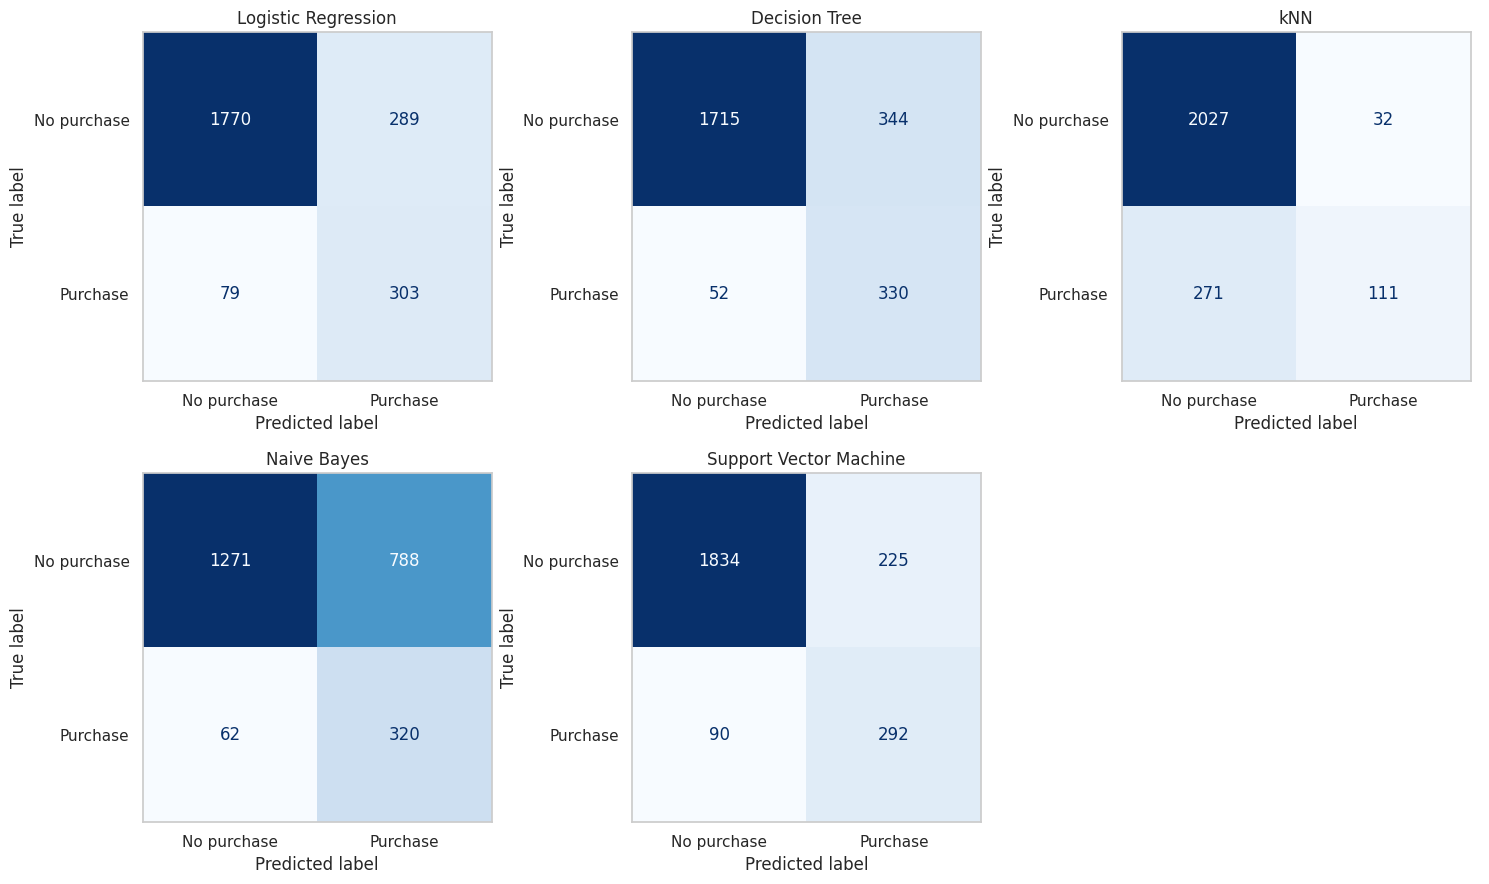

In [27]:
# Confusion matrix: rows = actual class, columns = predicted class
# Confusion matrices
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes = axes.ravel()
for ax, (name, m) in zip(axes, fitted.items()):
    cm = confusion_matrix(y_test, m.predict(X_test))
    ConfusionMatrixDisplay(cm, display_labels=["No purchase", "Purchase"]).plot(
        ax=ax, cmap="Blues", colorbar=False, values_format="d")
    ax.set_title(name)
    ax.grid(False)
# Hide the unused sixth panel
for ax in axes[len(fitted):]:
    ax.axis("off")
plt.tight_layout(); plt.show()

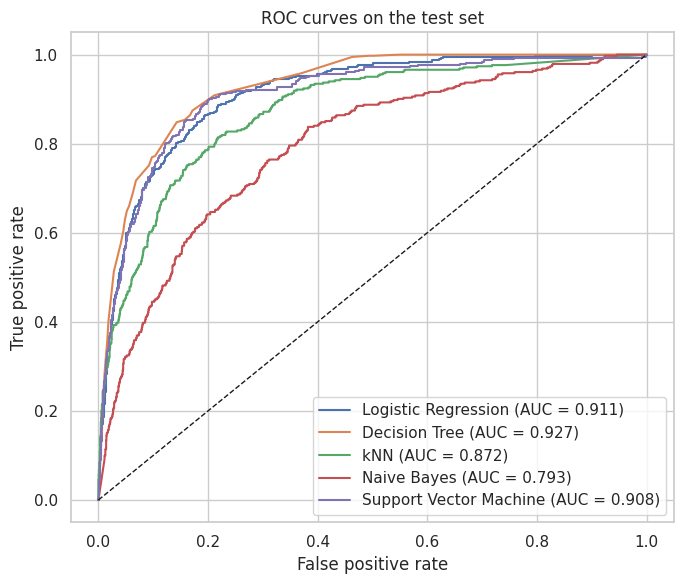

In [29]:
# ROC curve: closer to the top-left corner is better; the dashed diagonal is random guessing
# ROC curves
plt.figure(figsize=(7, 6))
for name, m in fitted.items():
    fpr, tpr, _ = roc_curve(y_test, get_scores(m, X_test))
    plt.plot(fpr, tpr, label=f"{name} (AUC = {results.loc[name, 'AUC']:.3f})")
plt.plot([0, 1], [0, 1], "k--", lw=1)
plt.xlabel("False positive rate"); plt.ylabel("True positive rate")
plt.title("ROC curves on the test set"); plt.legend(loc="lower right")
plt.tight_layout(); plt.show()

In [31]:
# Per-class precision, recall and F1 for every model
for name, m in fitted.items():
    print("=" * 60)
    print(name)
    print(classification_report(y_test, m.predict(X_test),
                                target_names=["No purchase", "Purchase"], digits=3))

Logistic Regression
              precision    recall  f1-score   support

 No purchase      0.957     0.860     0.906      2059
    Purchase      0.512     0.793     0.622       382

    accuracy                          0.849      2441
   macro avg      0.735     0.826     0.764      2441
weighted avg      0.888     0.849     0.861      2441

Decision Tree
              precision    recall  f1-score   support

 No purchase      0.971     0.833     0.896      2059
    Purchase      0.490     0.864     0.625       382

    accuracy                          0.838      2441
   macro avg      0.730     0.848     0.761      2441
weighted avg      0.895     0.838     0.854      2441

kNN
              precision    recall  f1-score   support

 No purchase      0.882     0.984     0.930      2059
    Purchase      0.776     0.291     0.423       382

    accuracy                          0.876      2441
   macro avg      0.829     0.638     0.677      2441
weighted avg      0.866     0.876   

In [33]:
# Factual read-out of the results above: use it as the starting point for your observations.
print("Best model per metric (test set):")
for metric in results.columns:
    best = results[metric].idxmax()
    print(f"  {metric:<10}: {best:<24} {results.loc[best, metric]:.4f}")

# Rank the models on each metric (1 = best) and average the ranks for an overall view
rank_table = results.rank(ascending=False, method="min").astype(int)
rank_table["Average rank"] = rank_table.mean(axis=1).round(2)
print("\nRank of each model on each metric (1 = best):")
display(rank_table.sort_values("Average rank"))
print("Lowest average rank:", rank_table["Average rank"].idxmin())

Best model per metric (test set):
  Accuracy  : kNN                      0.8759
  AUC       : Decision Tree            0.9272
  Precision : kNN                      0.7762
  Recall    : Decision Tree            0.8639
  F1        : Support Vector Machine   0.6496
  MCC       : Support Vector Machine   0.5826

Rank of each model on each metric (1 = best):


,Accuracy,AUC,Precision,Recall,F1,MCC,Average rank
ML Model Name,,,,,,,
Support Vector Machine,2,3,2,4,1,1,2.17
Decision Tree,4,1,4,1,2,2,2.33
Logistic Regression,3,2,3,3,3,3,2.83
kNN,1,4,1,5,5,4,3.33
Naive Bayes,5,5,5,2,4,5,4.33


Lowest average rank: Support Vector Machine


## 8. Observations

Results are on the held-out test set of 2,441 sessions (382 purchases). Only about 84% of sessions are "no purchase", so a model that always predicts "no purchase" would already reach about 84% accuracy. Accuracy is therefore read together with AUC, Recall, F1 and MCC.

| ML Model Name | Observation about model performance |
|---|---|
| Logistic Regression | A steady all-rounder: Accuracy 0.8492, AUC 0.9108 (2nd best), Recall 0.7932 and MCC 0.5534, and 3rd on every other metric. Train and test scores are almost identical (AUC 0.9070 vs 0.9108), so it generalises without overfitting. Precision is only 0.5118, meaning about half of its "purchase" predictions are false alarms, which is the cost of using balanced class weights to catch more buyers. |
| Decision Tree | Best AUC (0.9272) and best Recall (0.8639), so it finds about 86% of the real buyers. The price is lower Precision (0.4896, 4th) and an Accuracy of 0.8378, which is actually below the roughly 84% obtained by always predicting "no purchase", so accuracy alone would understate this model. A shallow tree (max_depth = 5, min_samples_leaf = 50) kept overfitting small: train AUC 0.9348 vs test AUC 0.9272. |
| kNN | Highest Accuracy (0.8759) and Precision (0.7762) but the worst Recall (0.2906) and F1 (0.4229): it rarely predicts "purchase", so it is usually right when it does but misses about 71% of the buyers. Training Accuracy and AUC are 1.0000 against a test AUC of 0.8722 (k = 31, distance weighting), so it has memorised the training data. Its high accuracy mostly comes from the majority class (Recall for "no purchase" is 0.984). |
| Naive Bayes | The weakest model overall: lowest Accuracy (0.6518), AUC (0.7929), Precision (0.2888) and MCC (0.3320). Its Recall of 0.8377 is 2nd best, but only because it labels too many sessions as purchases (just 61.7% of non-buyers are classified correctly). Train and test scores are nearly identical (Accuracy 0.6533 vs 0.6518), so this is a poor fit rather than overfitting, plausibly because the independence assumption does not hold: the heatmap shows strongly correlated features (BounceRates/ExitRates, ProductRelated/ProductRelated_Duration) and the one-hot columns are not Gaussian. |
| Support Vector Machine | Best F1 (0.6496) and MCC (0.5826), 2nd on Accuracy (0.8710) and Precision (0.5648), which gives the lowest average rank (2.17). It balances false alarms and missed buyers better than the other models (Recall 0.7644, 4th), and its AUC of 0.9080 is within 0.003 of Logistic Regression. The generalisation gap is small (train AUC 0.9289 vs test 0.9080), but it was the slowest to tune (39.2 s against 0.4 to 8.1 s for the others). |
| **Overall winner** | **Support Vector Machine.** It has the best MCC (0.5826) and F1 (0.6496), the two metrics that handle class imbalance best, and the lowest average rank (2.17). The margin over the Decision Tree is small (MCC 0.5663), and the Decision Tree is better on AUC (0.9272) and Recall (0.8639) and much faster to tune (1.7 s vs 39.2 s), so it would be the better choice if catching as many buyers as possible matters more than avoiding false alarms. |

## 9. Save artefacts for GitHub and Streamlit

In [35]:
# Save every fitted pipeline (preprocessing + model) so the app can take raw CSV input
os.makedirs("model", exist_ok=True)

def slug(name):
    return name.lower().replace(" ", "_")

saved = {}
for name, m in fitted.items():
    path = f"model/{slug(name)}.joblib"
    joblib.dump(m, path)
    saved[name] = path

# Metadata the Streamlit app can read: column names, model file paths, library version
feature_info = {
    "target": TARGET,
    "feature_columns": list(X.columns),
    "numeric_columns": NUMERIC,
    "categorical_columns": CATEGORICAL,
    "models": saved,
    "sklearn_version": sklearn.__version__,
}
with open("model/feature_info.json", "w") as f:
    json.dump(feature_info, f, indent=2)

# requirements.txt for Streamlit Cloud; scikit-learn is pinned to the version used for training
with open("requirements.txt", "w") as f:
    f.write("\n".join([
        "streamlit",
        f"scikit-learn=={sklearn.__version__}",
        "pandas",
        "numpy",
        "joblib",
        "matplotlib",
        "seaborn",
    ]) + "\n")

print("Saved model files:")
for name, p in saved.items():
    print(f"  {p:<45} {os.path.getsize(p)/1024:8.1f} KB")
print("\nAlso written: model/feature_info.json, requirements.txt, test_data.csv, metrics_results.csv")
print("\nrequirements.txt:\n" + open("requirements.txt").read())

Saved model files:
  model/logistic_regression.joblib                   5.8 KB
  model/decision_tree.joblib                        10.3 KB
  model/knn.joblib                                5650.0 KB
  model/naive_bayes.joblib                           7.4 KB
  model/support_vector_machine.joblib             2449.8 KB

Also written: model/feature_info.json, requirements.txt, test_data.csv, metrics_results.csv

requirements.txt:
streamlit
scikit-learn==1.9.1
pandas
numpy
joblib
matplotlib
seaborn



In [37]:
# README helper: comparison table in the exact column layout the assignment asks for.
def md_table(frame, first_col):
    cols = [first_col] + list(frame.columns)
    lines = ["| " + " | ".join(cols) + " |", "|" + "|".join(["---"] * len(cols)) + "|"]
    for idx, row in frame.iterrows():
        lines.append("| " + " | ".join([str(idx)] + [f"{v:.4f}" for v in row.values]) + " |")
    return "\n".join(lines)

comparison_md = md_table(results, "ML Model Name")
params_md = "| ML Model Name | Best hyper-parameters (3-fold CV, AUC) |\n|---|---|\n" + "\n".join(
    f"| {r['Model']} | {r['Best parameters']} |" for _, r in search_df.iterrows())

with open("README_tables.md", "w") as f:
    f.write("## Model comparison (test set)\n\n" + comparison_md + "\n\n## Tuned hyper-parameters\n\n" + params_md + "\n")

print(comparison_md)
print()
print(params_md)

| ML Model Name | Accuracy | AUC | Precision | Recall | F1 | MCC |
|---|---|---|---|---|---|---|
| Logistic Regression | 0.8492 | 0.9108 | 0.5118 | 0.7932 | 0.6222 | 0.5534 |
| Decision Tree | 0.8378 | 0.9272 | 0.4896 | 0.8639 | 0.6250 | 0.5663 |
| kNN | 0.8759 | 0.8722 | 0.7762 | 0.2906 | 0.4229 | 0.4255 |
| Naive Bayes | 0.6518 | 0.7929 | 0.2888 | 0.8377 | 0.4295 | 0.3320 |
| Support Vector Machine | 0.8710 | 0.9080 | 0.5648 | 0.7644 | 0.6496 | 0.5826 |

| ML Model Name | Best hyper-parameters (3-fold CV, AUC) |
|---|---|
| Logistic Regression | {'C': 0.1} |
| Decision Tree | {'max_depth': 5, 'min_samples_leaf': 50} |
| kNN | {'n_neighbors': 31, 'weights': 'distance'} |
| Naive Bayes | {'var_smoothing': 0.001} |
| Support Vector Machine | {'C': 5, 'gamma': 0.01} |


## 10. Sanity check – reload exactly what the Streamlit app will load
The app will read `test_data.csv` and the saved model files, so this cell repeats that path and confirms the numbers match Section 7.

In [39]:
# Simulate the app: read the test CSV and split off the target column
app_test = pd.read_csv("test_data.csv")
X_app, y_app = app_test.drop(columns=[TARGET]), app_test[TARGET]

problems = []
# Reload each model from disk and compare AUC/MCC with the numbers from Section 7
for name, path in saved.items():
    reloaded = joblib.load(path)
    r = evaluate(reloaded, X_app, y_app)
    if abs(r["AUC"] - results.loc[name, "AUC"]) > 1e-3 or abs(r["MCC"] - results.loc[name, "MCC"]) > 1e-3:
        problems.append(name)
    print(f"{name:<24} AUC {r['AUC']:.4f}  MCC {r['MCC']:.4f}")

print("\nAll reloaded models reproduce the notebook results." if not problems else f"\nMismatch for: {problems}")

Logistic Regression      AUC 0.9108  MCC 0.5534
Decision Tree            AUC 0.9272  MCC 0.5663
kNN                      AUC 0.8722  MCC 0.4255
Naive Bayes              AUC 0.7929  MCC 0.3320
Support Vector Machine   AUC 0.9080  MCC 0.5826

All reloaded models reproduce the notebook results.
